# ML Model with actual goals

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import xgboost as xgb
import warnings
from sklearn.linear_model import LinearRegression

NUM_OF_COUNTRIES = 5
NUM_OF_SEASONS = 25
NUM_OF_MATCHES = 9130
NUM_OF_MATCHES_IN_A_SEASON = 1826
AVG_HF_ADV = 0.3672508214676889  # from DB
AVG_GA = 2.7175246440306681  # from DB
SEED = 1893

np.random.seed(SEED)
warnings.filterwarnings('ignore')


In [2]:
def score_from_amount_and_diff(amount, diff):
    if diff < 0:
        home_score = (amount + diff) / 2
        away_score = home_score - diff
    else:
        away_score = (amount - diff) / 2
        home_score = away_score + diff

    # cut excess floating numbers
    if (home_score - int(home_score)) == 0 and (away_score - int(away_score)) == 0:
        home_score = int(home_score)
        away_score = int(away_score)

    return home_score, away_score


def print_formatted_pred_score(country, season, matchnumber, ht_name, at_name, ht_pred_score, at_pred_score, ht_actual_score, at_actual_score):
    print("%4s %3s %3s %20s %20s %15s | %6s" %
          (country, season, matchnumber, ht_name, at_name,
           str(ht_pred_score)[0:4] + ":" + str(at_pred_score)[0:4],
           f"{ht_actual_score}:{at_actual_score}"))


def calc_mae(y_pred, y):
    mae = 0.0
    for pred, actual_value in zip(y_pred, y):
        if type(pred) == list:
            mae += np.abs((float(pred[0]) - float(actual_value)))
        else:
            mae += np.abs((float(pred) - float(actual_value)))
    return mae / len(y)


def calc_mse(y_pred, y):
    mse = 0.0
    for pred, actual_value in zip(y_pred, y):
        if type(pred) == list:
            mse += np.square((float(pred[0]) - float(actual_value)))
        else:
            mse += np.square((float(pred) - float(actual_value)))
    return mse / len(y)



In [3]:
df_matches = pd.read_csv('matches_ag.csv', sep=';')

df_matches["is_eng"] = df_matches["country"].apply(lambda x: 1 if x == "ENG" else 0)
df_matches["is_esp"] = df_matches["country"].apply(lambda x: 1 if x == "ESP" else 0)
df_matches["is_fra"] = df_matches["country"].apply(lambda x: 1 if x == "FRA" else 0)
df_matches["is_ger"] = df_matches["country"].apply(lambda x: 1 if x == "GER" else 0)
df_matches["is_ita"] = df_matches["country"].apply(lambda x: 1 if x == "ITA" else 0)

all_features = [
    "ht_curr_eff_chancediff", "at_curr_eff_chancediff",
    "ht_past_chancediff_combined", "at_past_chancediff_combined",
    "ht_curr_eff_chanceamount", "at_curr_eff_chanceamount",
    "ht_past_chanceamount", "at_past_chanceamount",
    "ht_fitness", "at_fitness",
    "ht_market_value_ln_relative", "at_market_value_ln_relative",
    "ht_curr_chancediff", "at_curr_chancediff",
    "ht_last_year_chancediff", "at_last_year_chancediff",
    "ht_curr_chanceamount", "at_curr_chanceamount",
    "ht_last_year_chanceamount", "at_last_year_chanceamount",
    "ht_market_value", "at_market_value",
    "ht_market_value_ln", "at_market_value_ln",
    "is_eng", "is_esp", "is_fra", "is_ger", "is_ita"
]


ga_feature_set_heuer_country = [
    "ht_curr_eff_chanceamount", "at_curr_eff_chanceamount",
    "ht_past_chanceamount", "at_past_chanceamount",
    "is_eng", "is_esp", "is_fra", "is_ger", "is_ita"
]

gd_feature_set_heuer_country = [
    "ht_curr_eff_chancediff", "at_curr_eff_chancediff", 
    "ht_past_chancediff_combined", "at_past_chancediff_combined",
    "ht_fitness", "at_fitness", 
    "ht_market_value_ln_relative", "at_market_value_ln_relative",
    "is_eng", "is_esp", "is_fra", "is_ger", "is_ita"
]

ga_feature_set_heuer = [
    "ht_curr_eff_chanceamount", "at_curr_eff_chanceamount",
    "ht_past_chanceamount", "at_past_chanceamount"
]

gd_feature_set_heuer = [
    "ht_curr_eff_chancediff", "at_curr_eff_chancediff", 
    "ht_past_chancediff_combined", "at_past_chancediff_combined",
    "ht_fitness", "at_fitness", 
    "ht_market_value_ln_relative", "at_market_value_ln_relative"
]

ga_selection = [
    "ht_curr_eff_chanceamount", "at_curr_eff_chanceamount",
    "ht_last_year_chanceamount", "at_last_year_chanceamount",
    "ht_market_value_ln_relative", "at_market_value_ln_relative",
    "is_eng", "is_esp", "is_fra", "is_ger", "is_ita"
]

gd_selection = [
    "ht_curr_eff_chancediff", "at_curr_eff_chancediff",
    "ht_last_year_chancediff", "at_last_year_chancediff",
    "ht_market_value_ln_relative", "at_market_value_ln_relative"
]
                  
ga_label = ["actual_goalamount"]
gd_label = ["actual_goaldiff"]

df_matches


,country,season,matchnumber,ht_name,at_name,ht_curr_eff_chancediff,at_curr_eff_chancediff,ht_past_chancediff_combined,at_past_chancediff_combined,ht_curr_eff_chanceamount,...,at_last_year_xg_amount,xg_amount,xg_diff,actual_goalamount,actual_goaldiff,is_eng,is_esp,is_fra,is_ger,is_ita
0,ENG,14,1,Queens Park Rangers,Hull,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,3.018240,0.783100,1,-1,1,0,0,0,0
1,ENG,14,1,Newcastle,Man City,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,2.446113,-0.514947,2,-2,1,0,0,0,0
2,ENG,14,1,Burnley,Chelsea,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,2.501101,-1.758819,4,-2,1,0,0,0,0
3,ENG,14,1,Arsenal,Crystal Palace,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,1.712261,1.395959,3,1,1,0,0,0,0
4,ENG,14,1,West Ham,Tottenham,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,2.870160,0.836040,1,-1,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9125,ITA,18,38,Frosinone,Chievo,-4.492426,-4.452152,-3.581579,-1.943421,-2.059192,...,0.959903,0.585014,0.537046,0,0,0,0,0,0,1
9126,ITA,18,38,Fiorentina,CFC Genoa,1.172165,-1.286395,1.539474,-1.361842,0.407509,...,1.172081,0.370430,0.221648,0,0,0,0,0,0,1
9127,ITA,18,38,Bologna,Napoli,-0.932129,5.242267,-1.497368,5.293421,-0.446689,...,1.795735,2.737759,-0.858041,5,1,0,0,0,0,1
9128,ITA,18,38,Inter,Empoli,2.881676,-3.462648,2.380263,-3.058772,1.042860,...,1.370037,4.515770,0.970270,3,1,0,0,0,0,1


## Data split

In [4]:
df_training, df_testing = df_matches.query(
    f"season < 18"), df_matches.query(f"season == 18")


## XG Boost baseline

In [5]:
ga_model = xgb.XGBRegressor(base_score=0.5, booster='gbtree', colsample_bylevel=1, colsample_bynode=1, colsample_bytree=1, gamma=0,
                            importance_type='gain', learning_rate=0.1, max_delta_step=0, max_depth=3, min_child_weight=1, missing=1,
                            n_estimators=100, n_jobs=1, nthread=None, objective='reg:squarederror', random_state=0, reg_alpha=0,
                            reg_lambda=1, scale_pos_weight=1, seed=SEED, silent=None, subsample=1, verbosity=1)

gd_model = xgb.XGBRegressor(base_score=0.5, booster='gbtree', colsample_bylevel=1, colsample_bynode=1, colsample_bytree=1, gamma=0,
                            importance_type='gain', learning_rate=0.1, max_delta_step=0, max_depth=3, min_child_weight=1, missing=1,
                            n_estimators=100, n_jobs=1, nthread=None, objective='reg:squarederror', random_state=0, reg_alpha=0,
                            reg_lambda=1, scale_pos_weight=1, seed=SEED, silent=None, subsample=1, verbosity=1)

ga_model.fit(df_training[all_features], df_training[ga_label])
gd_model.fit(df_training[all_features], df_training[gd_label])

ga_abs_error = calc_mae(ga_model.predict(df_testing[all_features]), df_testing[ga_label].values)
gd_abs_error = calc_mae(gd_model.predict(
    df_testing[all_features]), df_testing[gd_label].values)

print("XGBoost regressor MAE goalamount:", ga_abs_error)
print("XGBoost regressor MAE goaldifference:", gd_abs_error)


XGBoost regressor MAE goalamount: 1.3136416318513215
XGBoost regressor MAE goaldifference: 1.26236267329951


## Model selection

In [6]:
class GeneralModel:
    def __init__(self):
        self.model = LinearRegression() 

    def fit(self, df, features, label):
        self.model.fit(df[features], df[label])

    def predict(self, df, features):
        return self.model.predict(df[features])

    def predict_single(self, row, features):
        return self.model.predict([row[features]])[0][0]

    def print_weights(self):
        print("General model weights:")
        print(self.model.coef_ , self.model.intercept_)


class WeightsPerMatchnumberModel:
    def __init__(self):
        self.models = []

    def fit(self, df, features, label):
        for i in range(1, 39):
            matchnumber_df = df.query(f"matchnumber == {i}")
            self.models.append(LinearRegression().fit(matchnumber_df[features],
                               matchnumber_df[label]))

    def predict(self, df, features):
        preds = []
        for index, row in df.iterrows():
            preds.append(
                self.models[row["matchnumber"]-1].predict([row[features]])[0])
        return preds

    def predict_single(self, row, features):
        return self.models[row["matchnumber"]-1].predict([row[features]])[0]

    def print_weights(self):
        print("Weights per matchnum model weights:")
        for model in self.models:
            print(model.coef_ , model.intercept_)


class SectionedModel:
    def __init__(self):
        self.models = [LinearRegression(), LinearRegression(),
                       LinearRegression()]

    def fit(self, df, features, label):
        first_df = df.query(f"(country == 'GER' and matchnumber < 18) or (country != 'GER' and matchnumber < 20)")
        second_df = df.query(
            f"(country == 'GER' and matchnumber >= 18 and matchnumber < 31) or (country != 'GER' and matchnumber >= 20 and matchnumber < 35)")
        third_df = df.query(
            f"(country == 'GER' and matchnumber >= 31) or (country != 'GER' and matchnumber >= 35)")
        if not first_df.empty:
            self.models[0].fit(first_df[features], first_df[label])
        else:
            self.models[0].fit([np.ones(len(features))], [[1]])
        if not second_df.empty:
            self.models[1].fit(second_df[features], second_df[label])
        else:
            self.models[1].fit([np.ones(len(features))], [[1]])
        if not third_df.empty:
            self.models[2].fit(third_df[features], third_df[label])
        else:
            self.models[2].fit([np.ones(len(features))], [[1]])
        

    def predict(self, df, features):
        preds = []
        for index, row in df.iterrows():
            if (row["country"] == "GER" and row["matchnumber"] < 18) or (row["country"] != 'GER' and row["matchnumber"] < 20):
                preds.append(self.models[0].predict([row[features]])[0])
            if (row["country"] == "GER" and row["matchnumber"] >= 18) and (row["matchnumber"] < 31) or (row["country"] != 'GER' and row["matchnumber"] >= 20 and row["matchnumber"] < 35):
                preds.append(self.models[1].predict([row[features]])[0])
            if (row["country"] == "GER" and row["matchnumber"] >= 31) or (row["country"] != 'GER' and row["matchnumber"] >= 35):
                preds.append(self.models[2].predict([row[features]])[0])
        return preds

    def predict_single(self, row, features):
        if (row["country"] == "GER" and row["matchnumber"] < 18) or (row["country"] != 'GER' and row["matchnumber"] < 20):
            return self.models[0].predict([row[features]])[0][0]
        if (row["country"] == "GER" and row["matchnumber"] >= 18) and (row["matchnumber"] < 31) or (row["country"] != 'GER' and row["matchnumber"] >= 20 and row["matchnumber"] < 35):
            return self.models[1].predict([row[features]])[0][0]
        if (row["country"] == "GER" and row["matchnumber"] >= 31) or (row["country"] != 'GER' and row["matchnumber"] >= 35):
            return self.models[2].predict([row[features]])[0][0]

    def print_weights(self):
        print("Sectioned model weights:")
        for model in self.models:
            print(model.coef_ , model.intercept_)


## K-Fold-Crossvalidation

In [7]:

do_crossvalidation = False

if do_crossvalidation:
    for feature_set_name, feature_set in zip(["all", "heuer", "heuer_country", "selection"], [(all_features, all_features), (ga_feature_set_heuer, gd_feature_set_heuer), (ga_feature_set_heuer_country, gd_feature_set_heuer_country), (ga_selection, gd_selection)]):
        for weight_set_name in ["general", "per_match_no", "sectioned"]:
            ga_validation_error, gd_validation_error = 0, 0
            for season in range(14,18):
                train_data, valid_data = df_training.query(
                    f"season != {season}"), df_training.query(f"season == {season}")

                if weight_set_name == "general":
                    ga_model, gd_model = GeneralModel(), GeneralModel()
                    ga_model.fit(
                        train_data, feature_set[0], ga_label)
                    gd_model.fit(
                        train_data, feature_set[1], gd_label)
                if weight_set_name == "per_match_no":
                    ga_model, gd_model = WeightsPerMatchnumberModel(), WeightsPerMatchnumberModel()
                    ga_model.fit(
                        train_data, feature_set[0], ga_label)
                    gd_model.fit(
                        train_data, feature_set[1], gd_label)
                if weight_set_name == "sectioned":
                    ga_model, gd_model = SectionedModel(), SectionedModel()
                    ga_model.fit(
                        train_data, feature_set[0], ga_label)
                    gd_model.fit(
                        train_data, feature_set[1], gd_label)
                
                ga_validation_error += (calc_mae(ga_model.predict(
                    valid_data, feature_set[0]), valid_data[ga_label].values)) * 0.25
                gd_validation_error += (calc_mae(gd_model.predict(
                    valid_data, feature_set[1]), valid_data[gd_label].values)) * 0.25

            print("%-9s %-12s " %
                (feature_set_name, weight_set_name))
            print("ga validation error:", ga_validation_error)
            print("gd validation error:", gd_validation_error, end="\n\n")

# selection general
# ga validation error: 1.3607579747313514

# heuer     general
# gd validation error: 1.2436963200161826


## Final models

In [8]:
ga_model = GeneralModel()
gd_model = GeneralModel()

ga_model.fit(df_training, ga_selection, ga_label)
gd_model.fit(df_training, gd_feature_set_heuer, gd_label)


ga_preds = ga_model.predict(
    df_testing, ga_selection)
gd_preds = gd_model.predict(
    df_testing, gd_feature_set_heuer)

print("Generalizazion error ga:", calc_mae(
    ga_preds, df_testing[ga_label].values))
print("Generalizazion error gd:", calc_mae(
    gd_preds, df_testing[gd_label].values))

print("--------")
ga_model.print_weights()
print("--------")
gd_model.print_weights()


[[2.64317832]
 [2.62196553]
 [2.66005669]
 ...
 [2.82471468]
 [2.96239832]
 [2.44246483]]
Generalizazion error ga: 1.3173416271825393
Generalizazion error gd: 1.2530948345031794
--------
General model weights:
[[ 0.06728508  0.06346524  0.02930311 -0.00294084  0.14005037  0.01072706
  -0.02231151  0.04177904 -0.12574252  0.08885204  0.01742295]] [2.59382031]
--------
General model weights:
[[ 0.05575362 -0.0452572  -0.02389229 -0.04555942  0.03399109 -0.01831862
   0.61308813 -0.52643515]] [0.4011134]


## training error

In [9]:
do_training_run = False

if do_training_run:
        error_dict = dict()
        for season in range(14,19):
                subject_df = df_matches.query(f"season <= {season}")

                ga_training_model = GeneralModel()
                gd_training_model = GeneralModel()

                ga_training_model.fit(subject_df, ga_selection, ga_label)
                gd_training_model.fit(subject_df, gd_feature_set_heuer, gd_label)

                for country in ["ENG","ESP","FRA","GER","ITA"]:
                        pred_df = subject_df.query(f"country == '{country}'")

                        if not season in error_dict.keys():
                                error_dict[season] = {}
                        if not country in error_dict[season].keys():
                                error_dict[season][country] = {
                                        "ga": 0, "gd": 0}

                        error_dict[season][country]["ga"] = calc_mae(
                            ga_training_model.predict(pred_df, ga_selection), pred_df[ga_label].values)
                        error_dict[season][country]["gd"] = calc_mae(
                            gd_training_model.predict(pred_df, gd_feature_set_heuer), pred_df[gd_label].values)
                        

        print("country;season;ga_error;gd_error")
        for a in error_dict.keys():
                for b in error_dict[a].keys():
                                print(str(b)+";"+str(a)+";" +
                                        str(error_dict[a][b]["ga"])+";"+str(error_dict[a][b]["gd"]))


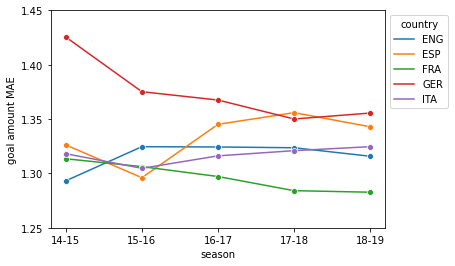

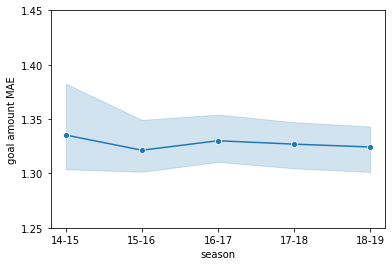

In [10]:
abs_error_df = pd.read_csv("abs_error.csv", sep=";")

g = sns.lineplot(x="season", y="ga_error",
                 hue="country", data=abs_error_df, marker="o")
sns.move_legend(g, "upper left", bbox_to_anchor=(1, 1))
plt.xticks([14, 15, 16, 17, 18], ["14-15", "15-16", "16-17", "17-18", "18-19"])
plt.yticks([1.25, 1.3, 1.35, 1.4, 1.45])
plt.ylabel("goal amount MAE")
plt.ylim(1.25, 1.45)
plt.show()

sns.lineplot(x="season", y="ga_error",
             data=abs_error_df, marker="o")
plt.ylabel("goal amount MAE")
plt.xticks([14, 15, 16, 17, 18], ["14-15", "15-16", "16-17", "17-18", "18-19"])
plt.yticks([1.25, 1.3, 1.35, 1.4, 1.45])
plt.ylim(1.25, 1.45)
plt.show()


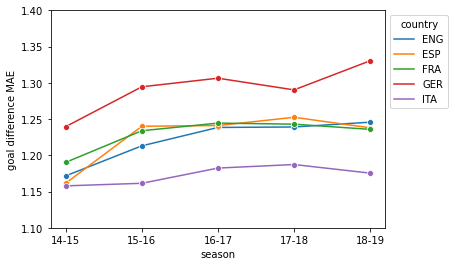

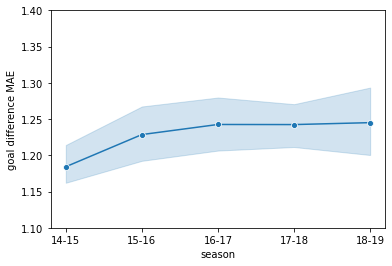

In [11]:
g = sns.lineplot(x="season", y="gd_error",
                 hue="country", data=abs_error_df,  marker="o")
sns.move_legend(g, "upper left", bbox_to_anchor=(1, 1))
plt.xticks([14, 15, 16, 17, 18], ["14-15", "15-16", "16-17", "17-18", "18-19"])
plt.ylabel("goal difference MAE")
plt.ylim(1.1, 1.4)
plt.show()

sns.lineplot(x="season", y="gd_error",
             data=abs_error_df,  marker="o")
plt.ylabel("goal difference MAE")
plt.xticks([14, 15, 16, 17, 18], ["14-15", "15-16", "16-17", "17-18", "18-19"])
plt.ylim(1.1, 1.4)
plt.show()


## prediction distribution

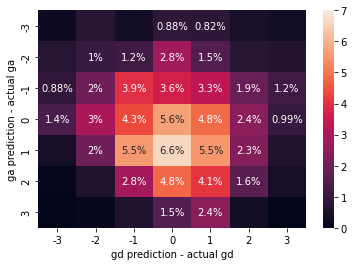

In [12]:
ga_abs_error, gd_abs_error = [],[]

ga_preds = ga_model.predict(df_testing, ga_selection)
gd_preds = gd_model.predict(df_testing, gd_feature_set_heuer)

for ga_pred, gd_pred, ga_actual, gd_actual in zip(ga_preds, gd_preds, df_testing["actual_goalamount"].values, df_testing["actual_goaldiff"].values):
        ga_abs_error.append(round(ga_pred[0]-ga_actual))
        gd_abs_error.append(round(gd_pred[0]-gd_actual))


data = dict()
for x in range(-10,10):
        data[x] = {}
        for y in range(-10, 10):
                data[x][y] = 0

for ga, gd in zip(ga_abs_error,gd_abs_error):
        data[ga][gd] += 1

sorted_keys = list(data.keys())
sorted_keys.sort()

ga,gd,count =[],[],[]

for key in sorted_keys:
        for x in data[key].keys():
                if key < 4 and key > -4 and x < 4 and x > -4:
                        ga.append(key)
                        gd.append(x)
                        count.append((data[key][x]/df_testing.shape[0])*100)

heatmap_df = pd.DataFrame()
heatmap_df["ga prediction - actual ga"] = ga
heatmap_df["gd prediction - actual gd"] = gd
heatmap_df["count"] = count

heatmap_df = heatmap_df.pivot(
    "ga prediction - actual ga", "gd prediction - actual gd", "count")

ax = sns.heatmap(heatmap_df, annot=True, vmax=7)
for t in ax.texts:
    if float(t.get_text()) > 0.75:
        t.set_text(t.get_text() + "%")
    else:
        t.set_text("")
plt.show()


## Prediction of a match

In [13]:
country, season, matchnumber, hometeam, awayteam = "ENG", 18, 20, "Southampton", "Man City"

subject_match = df_matches.query(f"season == {season} and matchnumber == {matchnumber} and ht_name == '{hometeam}'")

ga_pred = ga_model.predict(subject_match, ga_selection)[0][0]
gd_pred = gd_model.predict(subject_match, gd_feature_set_heuer)[0][0]
ht_score, at_score = score_from_amount_and_diff(ga_pred, gd_pred)

print(f"{country} - season: {season} - match week: {matchnumber} | {hometeam} vs. {awayteam}")
print("Bias of the goal amount model:", round(ga_model.model.intercept_[0],2))
print("Bias of the goal difference model:", round(gd_model.model.intercept_[0],2))
print()

print("Final predicted goal amount:", round(ga_pred, 2))
print("Final predicted goal difference:", round(gd_pred, 2))
print("Final predicted result:", round(ht_score,2),":",round(at_score,2))
print("Actual goal amount: 4")
print("Actual goal difference: -2")
print("Actual result: 1:3")
print()

print("Absolute error goal amount: |2.95 - 4| = 1.05")
print("Absolute error goal difference: |(-0.96) - (-2)| = 1.04")


ENG - season: 18 - match week: 20 | Southampton vs. Man City
Bias of the goal amount model: 2.59
Bias of the goal difference model: 0.4

Final predicted goal amount: 2.95
Final predicted goal difference: -0.96
Final predicted result: 0.99 : 1.96
Actual goal amount: 4
Actual goal difference: -2
Actual result: 1:3

Absolute error goal amount: |2.95 - 4| = 1.05
Absolute error goal difference: |(-0.96) - (-2)| = 1.04


## Prediction plotting

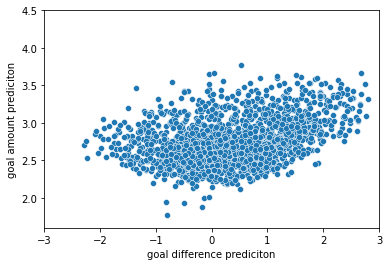

In [37]:
ga_preds_unpacked, gd_preds_unpacked = [], []

for ga, gd in zip(ga_preds, gd_preds):
    ga_preds_unpacked.append(ga[0])
    gd_preds_unpacked.append(gd[0])

# vs Heuer
sns.scatterplot(gd_preds_unpacked, ga_preds_unpacked)
plt.ylabel("goal amount prediciton")
plt.xlabel("goal difference prediciton")
plt.ylim(1.6, 4.5)
plt.xlim(-3, 3)

plt.show()


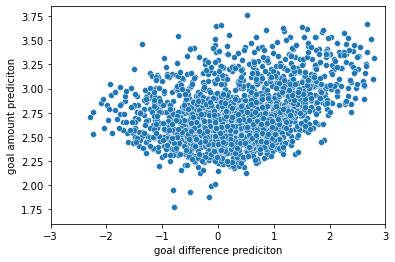

In [38]:
# vs xG-Regression
sns.scatterplot(gd_preds_unpacked, ga_preds_unpacked)
plt.ylabel("goal amount prediciton")
plt.xlabel("goal difference prediciton")
plt.ylim(1.6, 3.85)
plt.xlim(-3, 3)

plt.show()
